# cfDNA representation benchmark (Figure 4b-e)

Reads tables from `../data/` and writes figures to `../output/`. Source notebooks are listed in `../../NOTEBOOK_PROVENANCE.tsv`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_binning_delfi_benchmark.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_binning_delfi_benchmark.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_binning_delfi_benchmark.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_binning_delfi_benchmark.tsv


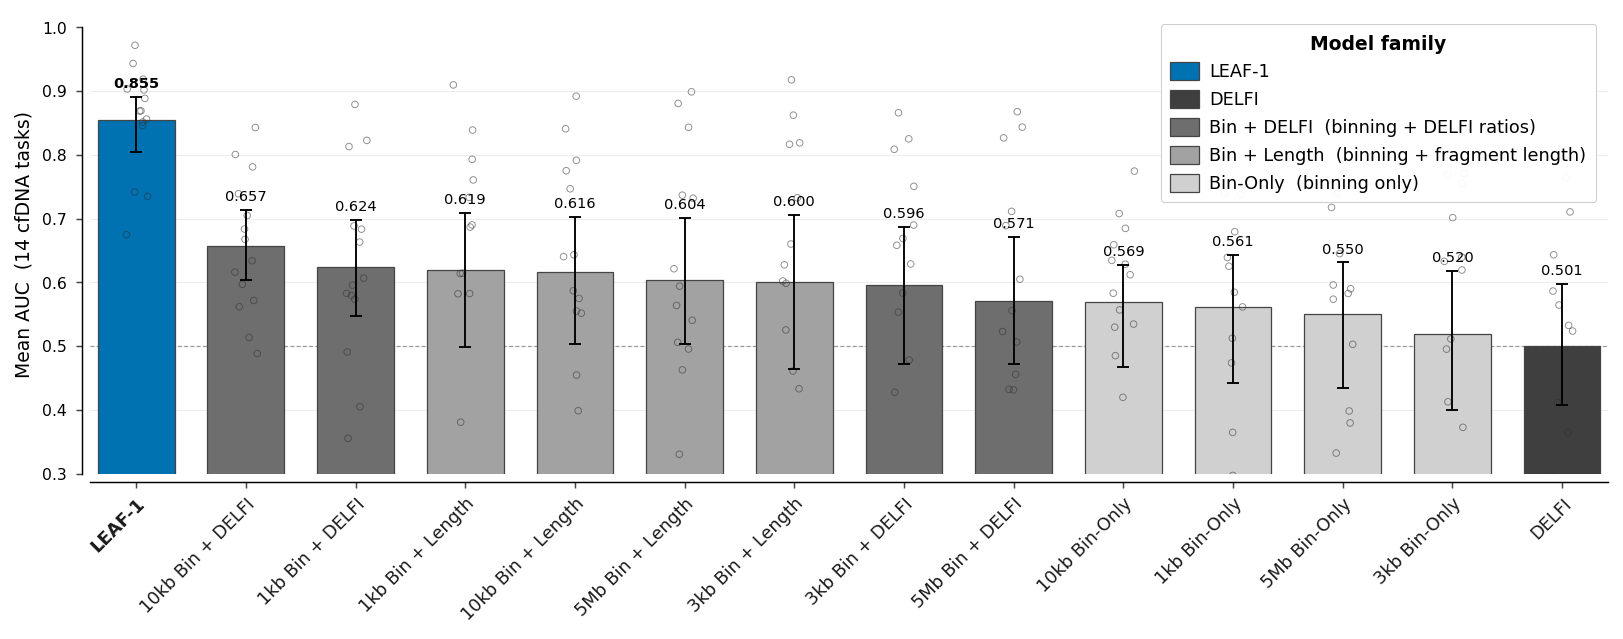

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 8,
    'axes.titlesize': 9, 'axes.labelsize': 8,
    'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
    'legend.fontsize': 6.5,
    'axes.linewidth': 0.7,
    'xtick.major.width': 0.7, 'ytick.major.width': 0.7,
    'xtick.major.size': 3, 'ytick.major.size': 3,
    'lines.linewidth': 1.0,
    'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

import matplotlib.transforms as mtrans
from matplotlib.patches import Patch
from scipy import stats as sp_stats

def bca_ci(vals, n_resamples=9999, seed=42):
    a = np.asarray(vals, dtype=float)
    r = sp_stats.bootstrap((a,), np.mean, n_resamples=n_resamples, confidence_level=0.95, method='BCa', random_state=np.random.default_rng(seed))
    return float(np.mean(a)), float(r.confidence_interval.low), float(r.confidence_interval.high)

auc_comb = pd.read_csv(DATA / 'per_task_auc_binning_delfi.csv').set_index('task_cancer')
LEAF_BLUE = OKABE_ITO['blue']; DELFI_GRAY = '#3F3F3F'; BIN_DELFI_GR = '#6E6E6E'; BINLEN_GR = '#A2A2A2'; BIN_GR = '#D0D0D0'; BAR_EDGE = '#444444'; JITTER_COL = '#303030'; ERR_COL = '#1A1A1A'
DISPLAY_LABEL = {'LEAF-1':'LEAF-1','DELFI':'DELFI','bin-5mb_delfi':'5Mb Bin + DELFI','bin-1K_delfi':'1kb Bin + DELFI','bin-3K_delfi':'3kb Bin + DELFI','bin-10K_delfi':'10kb Bin + DELFI','binlen-5mb':'5Mb Bin + Length','binlen-1K':'1kb Bin + Length','binlen-3K':'3kb Bin + Length','binlen-10K':'10kb Bin + Length','bin-5mb':'5Mb Bin-Only','bin-1K':'1kb Bin-Only','bin-3K':'3kb Bin-Only','bin-10K':'10kb Bin-Only'}
def bar_color(m):
    if m == 'LEAF-1': return LEAF_BLUE
    if m == 'DELFI': return DELFI_GRAY
    if m.endswith('_delfi'): return BIN_DELFI_GR
    if m.startswith('binlen-'): return BINLEN_GR
    return BIN_GR
order = sorted(list(auc_comb.columns), key=lambda m: -auc_comb[m].mean())
fig, ax = plt.subplots(figsize=(11.0, 4.5)); x = np.arange(len(order))
means=[]; err_lo=[]; err_hi=[]
for m in order:
    mu, lo, hi = bca_ci(auc_comb[m].values); means.append(mu); err_lo.append(mu-lo); err_hi.append(hi-mu)
ax.bar(x, means, width=0.7, color=[bar_color(m) for m in order], edgecolor=BAR_EDGE, linewidth=0.6, zorder=2, yerr=[err_lo, err_hi], capsize=3, error_kw={'linewidth':0.9,'capthick':0.9,'color':ERR_COL,'zorder':4})
yticks=[0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]
for yt in yticks[1:-1]: ax.axhline(yt, color='#EAEAEA', lw=0.4, zorder=0)
ax.axhline(0.5, color='#999999', linestyle=(0,(3,2)), linewidth=0.6, zorder=1)
rng=np.random.default_rng(42)
for i,m in enumerate(order):
    vals=auc_comb[m].values; jit=rng.uniform(-0.11,0.11,size=len(vals)); ax.scatter(np.full(len(vals),i)+jit, vals, facecolors='none', edgecolors=JITTER_COL, linewidth=0.45, alpha=0.55, s=10, zorder=3)
for i,(mu,eh) in enumerate(zip(means,err_hi)): ax.text(i, mu+eh+0.010, f'{mu:.3f}', ha='center', va='bottom', fontsize=7, fontweight='bold' if order[i]=='LEAF-1' else 'normal')
ax.set_ylabel('Mean AUC  (14 cfDNA tasks)', fontsize=9); ax.set_xticks(x); ax.set_xticklabels(['']*len(x)); ax.tick_params(axis='x', which='major', length=3, pad=2, color='#444444')
trans=mtrans.blended_transform_factory(ax.transData, ax.transAxes); offset=mtrans.ScaledTranslation(0,-10/72.0,fig.dpi_scale_trans)
for xi,m in zip(x, order): ax.text(xi,0,DISPLAY_LABEL.get(m,m), transform=trans+offset, rotation=45, ha='right', va='top', rotation_mode='anchor', fontsize=8.5, fontweight='bold' if m=='LEAF-1' else 'normal', color='#1A1A1A', clip_on=False)
ax.set_yticks(yticks); ax.set_ylim(0.30,1.02); XPAD=0.42; ax.set_xlim(x[0]-XPAD,x[-1]+XPAD); ax.spines['left'].set_position(('outward',4)); ax.spines['bottom'].set_position(('outward',4)); ax.spines['bottom'].set_bounds(x[0]-XPAD,x[-1]+XPAD); ax.spines['left'].set_bounds(yticks[0],yticks[-1]); ax.tick_params(axis='y', which='both', length=3, pad=4, color='#444444')
legend_handles=[Patch(facecolor=LEAF_BLUE, edgecolor=BAR_EDGE, linewidth=0.6, label='LEAF-1'), Patch(facecolor=DELFI_GRAY, edgecolor=BAR_EDGE, linewidth=0.6, label='DELFI'), Patch(facecolor=BIN_DELFI_GR, edgecolor=BAR_EDGE, linewidth=0.6, label='Bin + DELFI  (binning + DELFI ratios)'), Patch(facecolor=BINLEN_GR, edgecolor=BAR_EDGE, linewidth=0.6, label='Bin + Length  (binning + fragment length)'), Patch(facecolor=BIN_GR, edgecolor=BAR_EDGE, linewidth=0.6, label='Bin-Only  (binning only)')]
leg=ax.legend(handles=legend_handles, loc='upper right', bbox_to_anchor=(0.998,0.998), ncol=1, frameon=True, framealpha=0.95, edgecolor='#CCCCCC', facecolor='white', fontsize=8.5, title='Model family', title_fontsize=9, handlelength=1.6, handleheight=1.2, handletextpad=0.6, borderpad=0.55, labelspacing=0.5); leg.get_frame().set_linewidth(0.5); leg.get_title().set_fontweight('bold')
plt.subplots_adjust(left=0.07,right=0.99,bottom=0.28,top=0.96); savefig(fig, OUT, 'cfdna_binning_delfi_benchmark', data=(pd.DataFrame({'method':order,'display_label':[DISPLAY_LABEL.get(m,m) for m in order],'mean_auc':means,'ci_low':[mu-e for mu,e in zip(means,err_lo)],'ci_high':[mu+e for mu,e in zip(means,err_hi)]})))

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_kmer_benchmark.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_kmer_benchmark.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_kmer_benchmark.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_kmer_benchmark.tsv


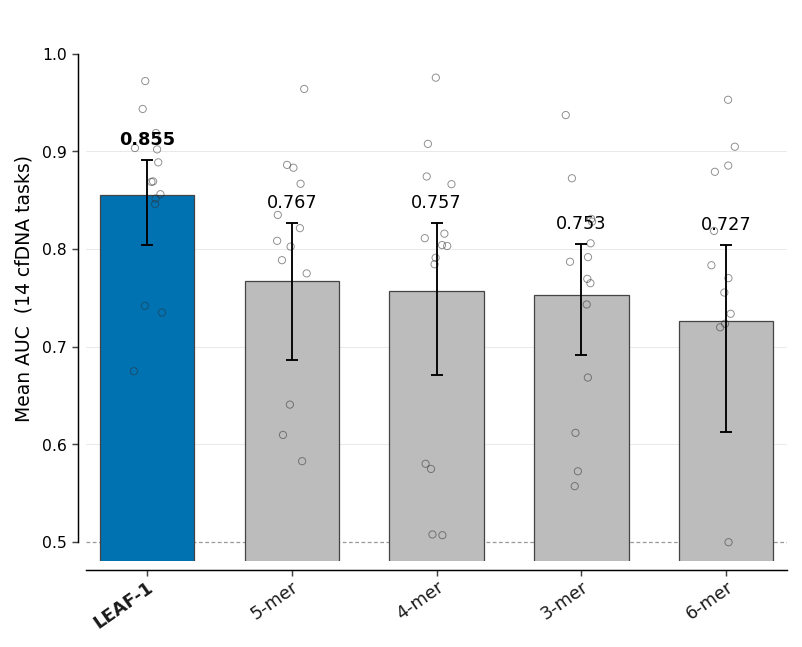

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 8,
    'axes.titlesize': 9, 'axes.labelsize': 8,
    'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
    'legend.fontsize': 6.5,
    'axes.linewidth': 0.7,
    'xtick.major.width': 0.7, 'ytick.major.width': 0.7,
    'xtick.major.size': 3, 'ytick.major.size': 3,
    'lines.linewidth': 1.0,
    'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

import matplotlib.transforms as mtrans
from matplotlib.patches import Patch
from scipy import stats as sp_stats

def bca_ci(vals, n_resamples=9999, seed=42):
    a = np.asarray(vals, dtype=float)
    r = sp_stats.bootstrap((a,), np.mean, n_resamples=n_resamples, confidence_level=0.95, method='BCa', random_state=np.random.default_rng(seed))
    return float(np.mean(a)), float(r.confidence_interval.low), float(r.confidence_interval.high)

auc_comb = pd.read_csv(DATA / 'per_task_auc_kmer.csv').set_index('task_cancer')
KMER_LABEL = {f'kmer-{k}': f'{k}-mer' for k in (3,4,5,6)}; DISPLAY_LABEL={'LEAF-1':'LEAF-1', **KMER_LABEL}
order = sorted(list(auc_comb.columns), key=lambda m: -auc_comb[m].mean())
fig, ax = plt.subplots(figsize=(5.5,4.5)); x=np.arange(len(order)); means=[]; err_lo=[]; err_hi=[]
for m in order:
    mu,lo,hi=bca_ci(auc_comb[m].values); means.append(mu); err_lo.append(mu-lo); err_hi.append(hi-mu)
ax.bar(x, means, width=0.65, color=[OKABE_ITO['blue'] if m=='LEAF-1' else '#BCBCBC' for m in order], edgecolor='#444444', linewidth=0.6, zorder=2, yerr=[err_lo,err_hi], capsize=3, error_kw={'linewidth':0.9,'capthick':0.9,'color':'#1A1A1A','zorder':4})
yticks=[0.5,0.6,0.7,0.8,0.9,1.0]
for yt in yticks[1:-1]: ax.axhline(yt, color='#E5E5E5', lw=0.4, zorder=0)
ax.axhline(0.5, color='#999999', linestyle=(0,(3,2)), linewidth=0.6, zorder=1)
rng=np.random.default_rng(42)
for i,m in enumerate(order):
    vals=auc_comb[m].values; jit=rng.uniform(-0.11,0.11,size=len(vals)); ax.scatter(np.full(len(vals),i)+jit, vals, facecolors='none', edgecolors='#303030', linewidth=0.45, alpha=0.55, s=12, zorder=3)
for i,(mu,eh) in enumerate(zip(means,err_hi)): ax.text(i, mu+eh+0.012, f'{mu:.3f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold' if order[i]=='LEAF-1' else 'normal')
ax.set_ylabel('Mean AUC  (14 cfDNA tasks)', fontsize=9); ax.set_xticks(x); ax.set_xticklabels(['']*len(x)); ax.tick_params(axis='x', which='major', length=3, pad=2, color='#444444')
trans=mtrans.blended_transform_factory(ax.transData, ax.transAxes); offset=mtrans.ScaledTranslation(0,-8/72.0,fig.dpi_scale_trans)
for xi,m in zip(x,order): ax.text(xi,0,DISPLAY_LABEL[m], transform=trans+offset, rotation=35, ha='right', va='top', rotation_mode='anchor', fontsize=8.5, fontweight='bold' if m=='LEAF-1' else 'normal', color='#1A1A1A', clip_on=False)
ax.set_yticks(yticks); ax.set_ylim(0.48,1.04); XPAD=0.42; ax.set_xlim(x[0]-XPAD,x[-1]+XPAD); ax.spines['left'].set_position(('outward',4)); ax.spines['bottom'].set_position(('outward',4)); ax.spines['bottom'].set_bounds(x[0]-XPAD,x[-1]+XPAD); ax.spines['left'].set_bounds(yticks[0],yticks[-1]); ax.tick_params(axis='y', which='both', length=3, pad=2, color='#444444')
plt.subplots_adjust(left=0.13,right=0.98,bottom=0.16,top=0.97); savefig(fig, OUT, 'cfdna_kmer_benchmark', data=(pd.DataFrame({'method':order,'display_label':[DISPLAY_LABEL[m] for m in order],'mean_auc':means,'ci_low':[mu-e for mu,e in zip(means,err_lo)],'ci_high':[mu+e for mu,e in zip(means,err_hi)]})))

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_external_lm_model_size.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_external_lm_model_size.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_external_lm_model_size.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_external_lm_model_size.tsv


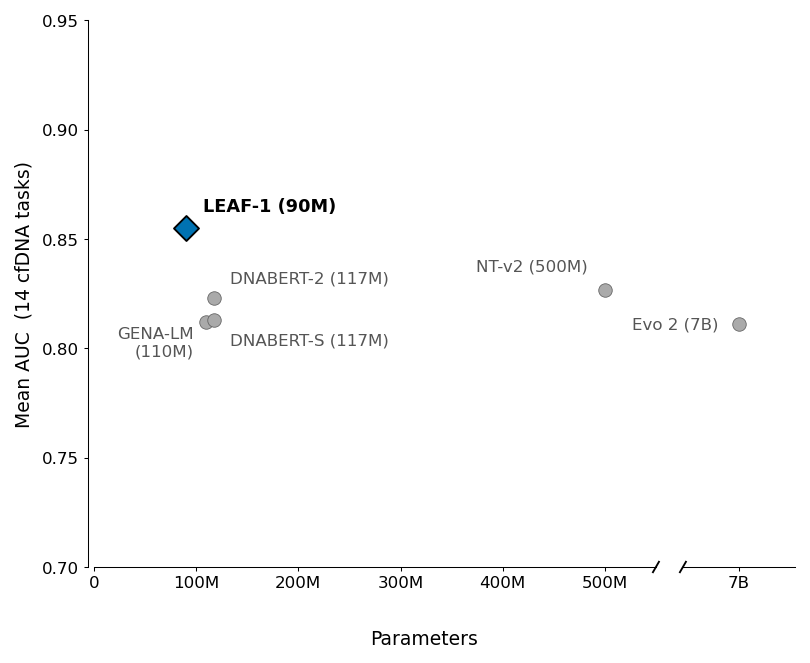

In [4]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'xtick.major.size': 2, 'ytick.major.size': 2,
    'xtick.major.pad': 2, 'ytick.major.pad': 2,
    'figure.dpi': 150, 'savefig.dpi': 600,
})

from matplotlib.lines import Line2D
from scipy import stats as sp_stats

def bca_ci_mean(vals, n_resamples=9999, seed=42):
    a=np.asarray(vals,dtype=float); r=sp_stats.bootstrap((a,), np.mean, n_resamples=n_resamples, confidence_level=0.95, method='BCa', random_state=np.random.default_rng(seed)); return float(np.mean(a)), float(r.confidence_interval.low), float(r.confidence_interval.high)
auc=pd.read_csv(DATA/'per_task_auc_external_main.csv').set_index('task_cancer'); params=pd.read_csv(DATA/'external_model_parameter_counts.csv').set_index('model')
order=['LEAF-1','gena-lm','dnabert2','dnabert-s','nt-v2','evo2']; display=params['display'].to_dict(); par=params['params'].to_dict()
summary={}
for m in order:
    mu,lo,hi=bca_ci_mean(auc[m].values); summary[m]={'mean_auc':mu,'ci_lo':lo,'ci_hi':hi,'params':par[m]}
def fmtp(p): return f'{p/1e9:.0f}B' if p>=1e9 else f'{p/1e6:.0f}M'
def label(m): return f"{display[m]}\n({fmtp(par[m])})" if m=='gena-lm' else f"{display[m]} ({fmtp(par[m])})"
LABEL_POS={'LEAF-1':(8,6,'left','bottom'),'gena-lm':(-6,-2,'right','top'),'dnabert2':(8,6,'left','bottom'),'dnabert-s':(8,-6,'left','top'),'nt-v2':(-8,8,'right','bottom'),'evo2':(-10,0,'right','center')}
fig,(ax_main,ax_far)=plt.subplots(1,2,sharey=True,figsize=(5.5,4.5),gridspec_kw={'width_ratios':[5,1],'wspace':0.08})
def plot_model(ax,m):
    s=summary[m]; x=s['params']; y=s['mean_auc']; leaf=m=='LEAF-1'; marker='D' if leaf else 'o'; color=OKABE_ITO['blue'] if leaf else '#AAAAAA'; size=72 if leaf else 42; ec='k' if leaf else '#666'; lw=0.9 if leaf else 0.4
    ax.scatter(x,y,marker=marker,color=color,s=size,edgecolors=ec,linewidths=lw,zorder=5 if leaf else 3)
    dx,dy,ha,va=LABEL_POS[m]
    ax.annotate(label(m),xy=(x,y),xytext=(dx,dy),textcoords='offset points',ha=ha,va=va,fontsize=8.5 if leaf else 8,fontweight='bold' if leaf else 'normal',color='k' if leaf else '#555',bbox=dict(boxstyle='round,pad=0.15',fc=ax.get_facecolor(),ec='none',alpha=0.95),clip_on=False,zorder=6)
for m in [m for m in order if par[m] < 1e9]: plot_model(ax_main,m)
for m in [m for m in order if par[m] >= 1e9]: plot_model(ax_far,m)
ax_main.set_xlim(0,550e6); ax_far.set_xlim(6.9e9,7.1e9); ax_main.set_ylim(0.7,0.95); ax_main.set_xticks([0,100e6,200e6,300e6,400e6,500e6]); ax_main.set_xticklabels(['0','100M','200M','300M','400M','500M']); ax_far.set_xticks([7e9]); ax_far.set_xticklabels(['7B'])
ax_main.set_ylabel('Mean AUC  (14 cfDNA tasks)', fontsize=9); fig.text(0.52,0.02,'Parameters',ha='center',va='bottom',fontsize=9)
ax_main.spines['right'].set_visible(False); ax_far.spines['left'].set_visible(False); ax_far.tick_params(left=False,labelleft=False)
for a in (ax_main, ax_far): a.spines['top'].set_visible(False); a.tick_params(labelsize=8)
ax_main.spines['left'].set_position(('outward',3)); fig.subplots_adjust(left=0.12,right=0.97,top=0.95,bottom=0.14)
fig.canvas.draw(); fig_w,fig_h=fig.get_size_inches(); tick_len=0.08; angle=60; dx=(tick_len*math.cos(math.radians(angle))/2)/fig_w; dy=(tick_len*math.sin(math.radians(angle))/2)/fig_h
for ax,cx in [(ax_main,1.0),(ax_far,0.0)]:
    p=fig.transFigure.inverted().transform(ax.transAxes.transform((cx,0.0))); fig.add_artist(Line2D([p[0]-dx,p[0]+dx],[p[1]-dy,p[1]+dy],transform=fig.transFigure,color='k',lw=0.9,clip_on=False))
savefig(fig, OUT, 'cfdna_external_lm_model_size', data=(pd.DataFrame([{'model':m,'display':display[m],'params':summary[m]['params'],'mean_auc':summary[m]['mean_auc'],'ci_low':summary[m]['ci_lo'],'ci_high':summary[m]['ci_hi']} for m in order])))

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_segment_ablation.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_segment_ablation.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_segment_ablation.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_segment_ablation.tsv


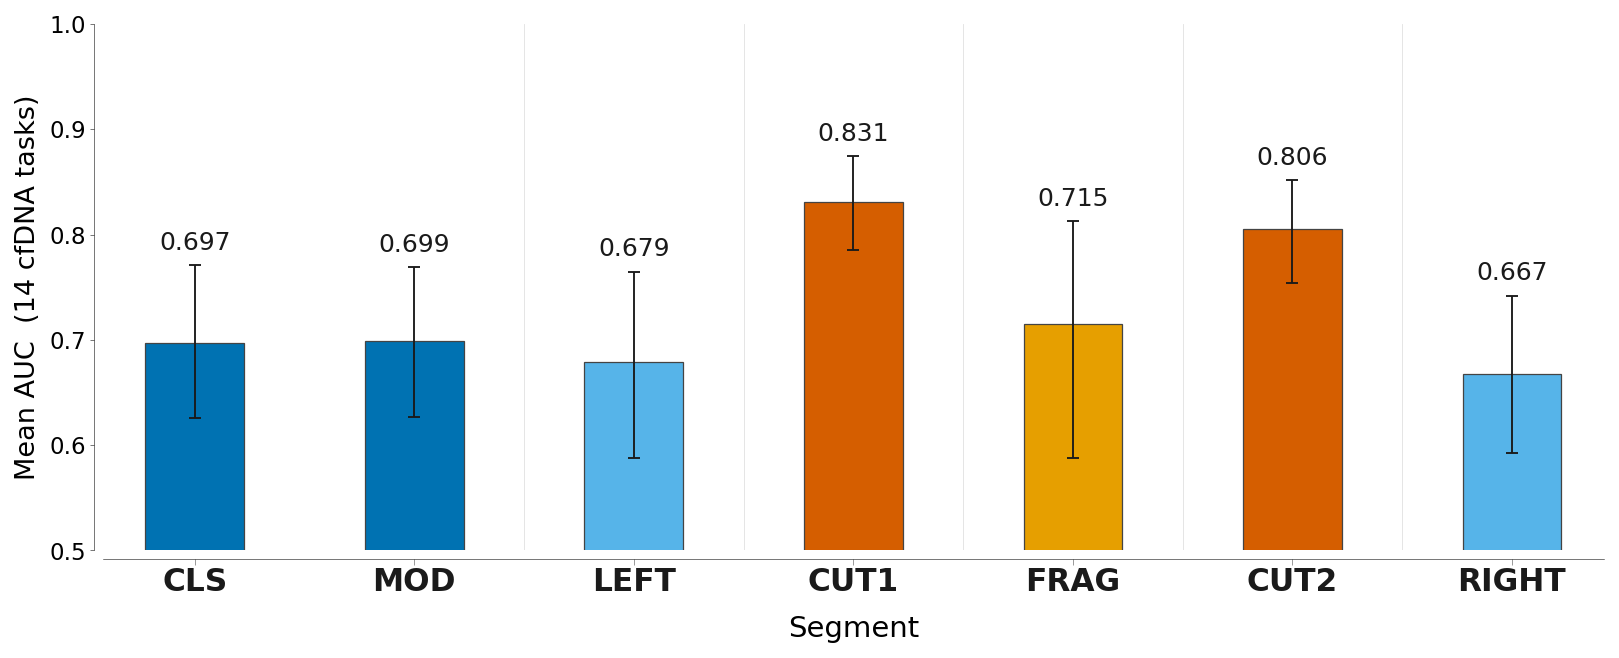

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica', 'Liberation Sans'],
    'font.size': 6,
    'axes.titlesize': 8,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 5,
    'axes.linewidth': 0.25,
    'xtick.major.width': 0.25, 'ytick.major.width': 0.25,
    'lines.linewidth': 0.75,
    'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

import matplotlib.transforms as mtrans

df = pd.read_csv(DATA / 'cfdna_segment_ablation_summary.csv')
order = ['CLS','MOD','LEFT','CUT1','FRAG','CUT2','RIGHT']
df['label'] = pd.Categorical(df['label'], order, ordered=True); df = df.sort_values('label')
group_colors = {'token': '#0072B2', 'flank': '#56B4E9', 'cut': '#D55E00', 'fragment': '#E69F00'}
colors = [group_colors[g] for g in df['group']]
fig, ax = plt.subplots(figsize=(11.0, 4.5)); xs=np.arange(len(df)); means=df['mean_auc'].values; err_lo=means-df['ci_low'].values; err_hi=df['ci_high'].values-means
ax.bar(xs, means, color=colors, width=0.45, linewidth=0.6, edgecolor='#444444', zorder=2)
ax.errorbar(xs, means, yerr=[err_lo,err_hi], fmt='none', ecolor='#1A1A1A', elinewidth=0.9, capsize=3, capthick=0.9, zorder=4)
for x_sep in [1.5,2.5,3.5,4.5,5.5]: ax.axvline(x_sep, color='#e0e0e0', linestyle='-', linewidth=0.4, zorder=0)
for xi, mu, eh in zip(xs, means, err_hi): ax.text(xi, mu+eh+0.010, f'{mu:.3f}', ha='center', va='bottom', fontsize=12, color='#1A1A1A')
ax.set_xticks(xs); ax.set_xticklabels(['']*len(xs)); ax.tick_params(axis='x', which='major', length=3, pad=2, color='#444444')
trans=mtrans.blended_transform_factory(ax.transData, ax.transAxes); offset=mtrans.ScaledTranslation(0,-8/72.0,fig.dpi_scale_trans)
for xi,label in zip(xs, df['label'].astype(str)): ax.text(xi,0,label,transform=trans+offset,ha='center',va='top',fontsize=15,fontweight='bold',color='#1A1A1A',clip_on=False)
ax.set_xlabel('Segment', fontsize=14, labelpad=22); ax.set_ylabel('Mean AUC  (14 cfDNA tasks)', fontsize=13); ax.tick_params(axis='y', labelsize=11); ax.set_ylim(0.5,1.0); XPAD=0.42; ax.set_xlim(xs[0]-XPAD,xs[-1]+XPAD); ax.spines['left'].set_position(('outward',4)); ax.spines['bottom'].set_position(('outward',4)); ax.spines['bottom'].set_bounds(xs[0]-XPAD,xs[-1]+XPAD)
plt.subplots_adjust(left=0.08,right=0.99,bottom=0.18,top=0.96); savefig(fig, OUT, 'cfdna_segment_ablation', data=(df[['label','group','mean_auc','ci_low','ci_high']]))